In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
words = open('names.txt', 'r').read().splitlines()
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [4]:
len(words)

32033

In [5]:
# build teh vacabulory of character and mapping to/from intergers

chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
vocab_size = len(itos)
print(vocab_size)
print(itos)

27
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:
# build the dataset

block_size = 3

def build_dataset(words):
  X, Y = [], []

  for w in words:
    context = [0]*block_size
    for ch in w+'.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X, Y

import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

print(Xtr.shape, Ytr.shape)
print(Xdev.shape, Ydev.shape)
print(Xte.shape, Yte.shape)

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [7]:
# MLP

n_emb = 10
n_hidden = 200

g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True

print(sum(p.nelement() for p in parameters))

11897


In [8]:
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 27.8817
  10000/ 200000: 2.9415
  20000/ 200000: 2.5069
  30000/ 200000: 2.7998
  40000/ 200000: 2.0261
  50000/ 200000: 2.5863
  60000/ 200000: 2.3420
  70000/ 200000: 2.0952
  80000/ 200000: 2.3454
  90000/ 200000: 2.2365
 100000/ 200000: 2.1080
 110000/ 200000: 2.3831
 120000/ 200000: 1.9898
 130000/ 200000: 2.4591
 140000/ 200000: 2.1910
 150000/ 200000: 2.1606
 160000/ 200000: 2.1811
 170000/ 200000: 1.7997
 180000/ 200000: 2.0962
 190000/ 200000: 1.8052


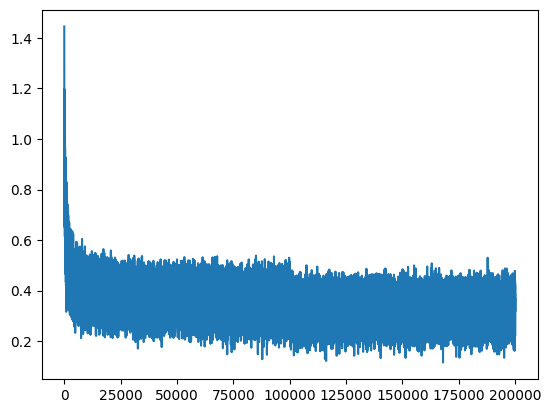

In [9]:
plt.plot(lossi)

In [10]:
@torch.no_grad()          # This decorator disables gradient tracking *************************
def split_loss(split: str):

  x, y = {
      'train': (Xtr, Ytr),
      'va;': (Xdev, Ydev),
      'test': (Xte, Yte)
  }[split]

  emb = C[x]

  embcat = emb.view(emb.shape[0], -1)
  h = torch.tanh(embcat @ W1 + b1)

  logits = h @ W2 + b2

  loss = F.cross_entropy(logits, y)
  print(f'{split}: {loss:.4f}')

split_loss('train')
split_loss('test')

train: 2.1277
test: 2.1674


In [11]:

# @torch.no_grad()          # This decorator disables gradient tracking ************************************ imp.
# Whatever happens in this function is assumed by torch to never required any gradients
# so it will not do any of the book-keeping that it does normally to keep the track of all the gradients
# in anticipation of an eventual backward pass
# all the tensor that get created here have the required_grad = False
# This save is memory and computational power at the backend


In [12]:
# Sample from the model
# Lets try creating new words using our model

g = torch.Generator().manual_seed(2147482647 + 10)

for _ in range(20):

  out = []
  context = [0]*block_size

  while True:
    # forward pass
    emb = C[torch.tensor(context)]
    embcat = emb.view(1, -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2

    probs = F.softmax(logits, dim = 1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)

    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

nyendiq.
utzaen.
edeno.
neleena.
cornebe.
jny.
osdaci.
bhaun.
jhanko.
azjuniah.
dynn.
dhaizia.
rylinna.
mizier.
cornett.
hastynslei.
azrielee.
haylah.
nikoriana.
krianyn.


In [13]:
# At initilization all 27 char are equally likely output
# so the initial probality for each char should be 1/27
# initial probality distribution should be linear
# from that we can calculate the loss which is -log likelihood

In [14]:
# Expected initial loss

-torch.tensor(1/27.0).log()

tensor(3.2958)

In [15]:
# this is much much lower that   0/200000: 27.8817

In [16]:
# 4D example
logits = torch.tensor([0.0, 0.0, 0.0, 0.0])
probs = torch.softmax(logits, dim=0)
loss = -probs[2].log()
probs, loss

(tensor([0.2500, 0.2500, 0.2500, 0.2500]), tensor(1.3863))

In [17]:
# Manupulating the logits ----> can results in change in loss

In [18]:
# 4D example
logits = torch.tensor([-3.0, 10.0, 0.0, 4.0]) * 10
probs = torch.softmax(logits, dim=0)
loss = -probs[2 ].log()
probs, loss

(tensor([0.0000e+00, 1.0000e+00, 3.7835e-44, 8.7565e-27]), tensor(99.9831))

In [19]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)
parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 27.8817


In [20]:
logits[0]

tensor([ -2.3527,  36.4366, -10.7306,   5.7165,  18.6409, -11.6998,  -2.1991,
          1.8535,  10.9996,  10.6730,  12.3507, -10.3809,   4.7243, -24.4257,
         -8.5909,   1.9024, -12.2744, -12.4751, -23.2778,  -2.0163,  25.8767,
         14.2108,  17.7691, -10.9204, -20.7335,   6.4560,  11.1615],
       grad_fn=<SelectBackward0>)

In [21]:
# logits have extream value difference

# this logits should be close to zero

In [22]:
# logits = h @ W2 + b2

# 1
# because we want roughly zero, we dont want to be adding bias of random numbers
# thus, we will do
# b2 = torch.randn(vocab_size, generator=g) * 0
# initially the bias is zero

# 2
# we want close to zero logits therefore
# we want smaller number in W2
# thus
# W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.1

In [23]:
# implementing above changes

n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01       #*******imp.
b2 = torch.randn(vocab_size, generator=g) * 0                      #*******imp.

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 3.3221


In [24]:
# roughly we want tensor(3.2958)
# -torch.tensor(1/27.0).log()

In [25]:
# implementing above changes

n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01       #*******imp.
b2 = torch.randn(vocab_size, generator=g) * 0                      #*******imp.

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3221
  10000/ 200000: 2.1900
  20000/ 200000: 2.4196
  30000/ 200000: 2.6067
  40000/ 200000: 2.0601
  50000/ 200000: 2.4988
  60000/ 200000: 2.3902
  70000/ 200000: 2.1344
  80000/ 200000: 2.3369
  90000/ 200000: 2.1299
 100000/ 200000: 1.8329
 110000/ 200000: 2.2053
 120000/ 200000: 1.8540
 130000/ 200000: 2.4566
 140000/ 200000: 2.1879
 150000/ 200000: 2.1118
 160000/ 200000: 1.8956
 170000/ 200000: 1.8644
 180000/ 200000: 2.0326
 190000/ 200000: 1.8417


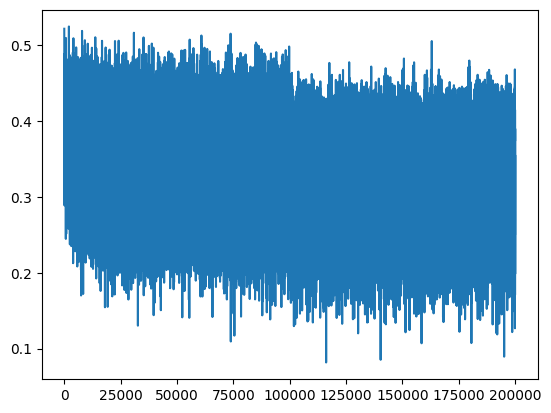

In [26]:
plt.plot(lossi)

In [27]:
split_loss('train')
split_loss('test')

train: 2.0696
test: 2.1328


In [28]:
# Sample from the model
# Lets try creating new words using our model

g = torch.Generator().manual_seed(2147482647 + 10)

for _ in range(20):

  out = []
  context = [0]*block_size

  while True:
    # forward pass
    emb = C[torch.tensor(context)]
    embcat = emb.view(1, -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2

    probs = F.softmax(logits, dim = 1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)

    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

nyeed.
quin.
hender.
holo.
anessaccenebe.
jna.
osdellenhaunushankeea.
junix.
addan.
dhara.
sar.
azing.
mizie.
aziranti.
has.
diseli.
azrielee.
heylah.
nikoliana.
kriszynsleia.


In [29]:
# there is a problem with h

(array([79.,  4.,  1.,  0.,  3.,  0.,  0.,  2.,  0.,  1.,  0.,  0.,  0.,
         0.,  0.,  2.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  2.,  0.,  0.,  0.,  0.,  1.,  2.,  2.,  2.,
         0.,  1.,  0.,  1.,  0.,  0.,  0.,  2.,  3.,  5., 85.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

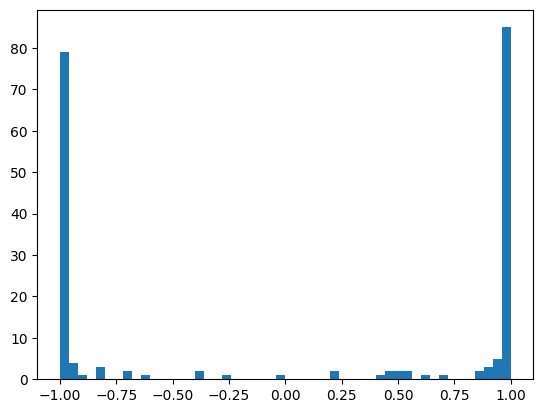

In [30]:
plt.hist(h.view(-1).tolist(), 50)

In [31]:
# implementing above changes

n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01       #*******imp.
b2 = torch.randn(vocab_size, generator=g) * 0                      #*******imp.

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 3.3221


In [32]:
h.shape

torch.Size([32, 200])

(array([2069.,  144.,  106.,   82.,   59.,   56.,   44.,   30.,   43.,
          26.,   16.,   38.,   16.,   32.,   24.,   14.,   28.,   27.,
          26.,   19.,   24.,   26.,   30.,   14.,   19.,   19.,   22.,
          26.,   18.,   12.,   10.,   33.,   27.,   32.,   17.,   24.,
          30.,   22.,   26.,   29.,   26.,   40.,   29.,   41.,   49.,
          64.,   62.,  100.,  188., 2442.]),
 array([-1.  , -0.96, -0.92, -0.88, -0.84, -0.8 , -0.76, -0.72, -0.68,
        -0.64, -0.6 , -0.56, -0.52, -0.48, -0.44, -0.4 , -0.36, -0.32,
        -0.28, -0.24, -0.2 , -0.16, -0.12, -0.08, -0.04,  0.  ,  0.04,
         0.08,  0.12,  0.16,  0.2 ,  0.24,  0.28,  0.32,  0.36,  0.4 ,
         0.44,  0.48,  0.52,  0.56,  0.6 ,  0.64,  0.68,  0.72,  0.76,
         0.8 ,  0.84,  0.88,  0.92,  0.96,  1.  ]),
 <BarContainer object of 50 artists>)

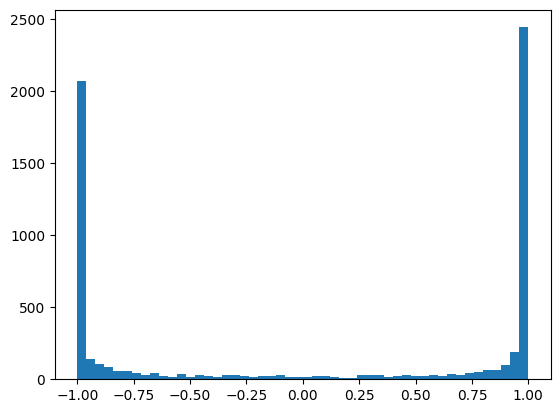

In [33]:
plt.hist(h.view(-1).tolist(), 50)

In [34]:
# Lot of values are '1' or '-1' in 'h'
# this is not good for us because
# grad will be zero - no optimization

# self.grad = (1 - t**2) * out.grad
# if t = 1 or t = -1 then grad=0

# def tanh(self):
#     x = self.data
#     t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
#     out = Value(t, (self,), "tanh")

#     def _backward():
#       self.grad = (1 - t**2) * out.grad

#     out._backward = _backward
#     return out

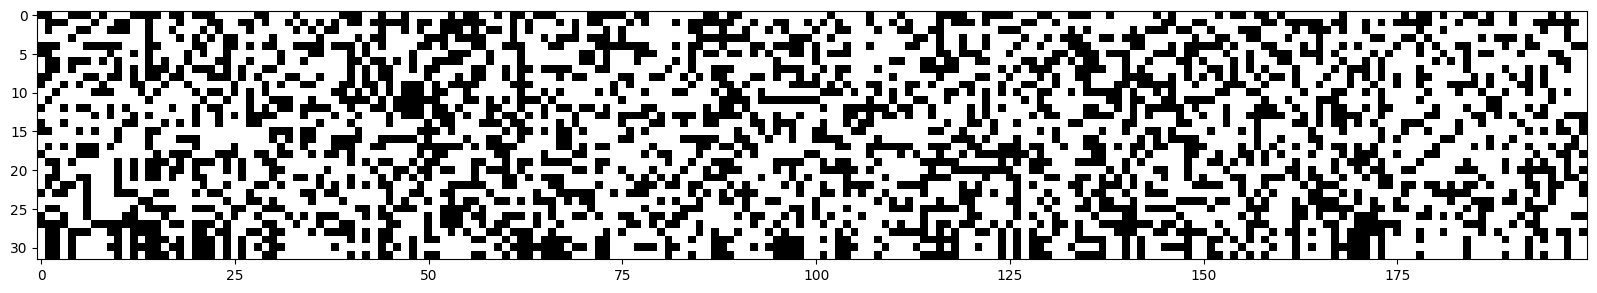

In [35]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99 , cmap = 'gray', interpolation='nearest')

In [36]:
# lot of whit inticates h.abs() > 0.99
# which will result in grad = 0

# NOTE:
# if whole column is white then that means that particular neuron will not activate
# i.e its a dead neuron
# in our case there are no dead neurons

In [37]:
# Why grad = 0 bad?
# if grad = 0 then we cant optimize that parameter parameter

(array([  2.,   2.,   1.,   4.,   2.,   4.,   6.,  15.,   5.,  25.,  32.,
         49.,  56.,  59.,  92., 119., 134., 197., 195., 221., 257., 275.,
        297., 341., 353., 375., 369., 349., 358., 362., 271., 312., 229.,
        206., 190., 167.,  87., 111.,  72.,  55.,  41.,  22.,  23.,  18.,
         17.,   8.,   5.,   7.,   2.,   1.]),
 array([-19.05793571, -18.31571732, -17.57349892, -16.83128052,
        -16.08906212, -15.34684372, -14.60462532, -13.86240692,
        -13.12018852, -12.37797012, -11.63575172, -10.89353333,
        -10.15131493,  -9.40909653,  -8.66687813,  -7.92465973,
         -7.18244133,  -6.44022293,  -5.69800453,  -4.95578613,
         -4.21356773,  -3.47134933,  -2.72913094,  -1.98691254,
         -1.24469414,  -0.50247574,   0.23974266,   0.98196106,
          1.72417946,   2.46639786,   3.20861626,   3.95083466,
          4.69305305,   5.43527145,   6.17748985,   6.91970825,
          7.66192665,   8.40414505,   9.14636345,   9.88858185,
         10.630800

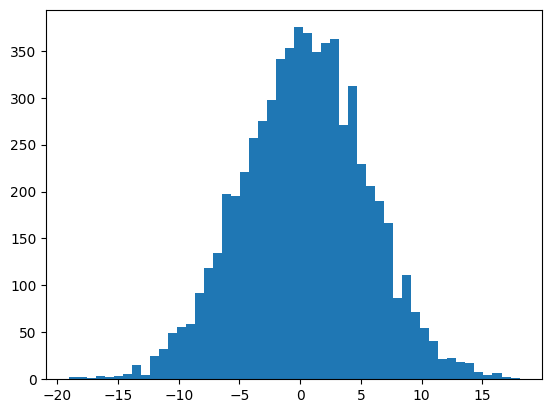

In [38]:
plt.hist(hpreact.view(-1).tolist(), 50)

In [39]:
# hpreact is too faar off from zero that is want causing this issue

In [40]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * 0.2     #*******imp.
b1 = torch.randn(n_hidden, generator=g) * 0.01                          #*******imp.

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i}/{max_step}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

  break

0/200000: 3.3135


(array([143., 172., 172., 161., 142., 151., 133., 116., 116., 143.,  95.,
        104., 126., 111., 119.,  91.,  86.,  90., 115., 100., 112., 122.,
        111.,  77., 103., 119., 100., 106.,  91.,  90., 117., 114., 116.,
        115., 107., 131., 111., 109., 114., 118., 142., 127., 162., 169.,
        152., 197., 184., 192., 208., 198.]),
 array([-9.98924255e-01, -9.58988956e-01, -9.19053657e-01, -8.79118358e-01,
        -8.39183059e-01, -7.99247760e-01, -7.59312460e-01, -7.19377161e-01,
        -6.79441862e-01, -6.39506563e-01, -5.99571264e-01, -5.59635965e-01,
        -5.19700665e-01, -4.79765366e-01, -4.39830067e-01, -3.99894768e-01,
        -3.59959469e-01, -3.20024170e-01, -2.80088871e-01, -2.40153571e-01,
        -2.00218272e-01, -1.60282973e-01, -1.20347674e-01, -8.04123747e-02,
        -4.04770756e-02, -5.41776419e-04,  3.93935227e-02,  7.93288219e-02,
         1.19264121e-01,  1.59199420e-01,  1.99134719e-01,  2.39070019e-01,
         2.79005318e-01,  3.18940617e-01,  3.58875

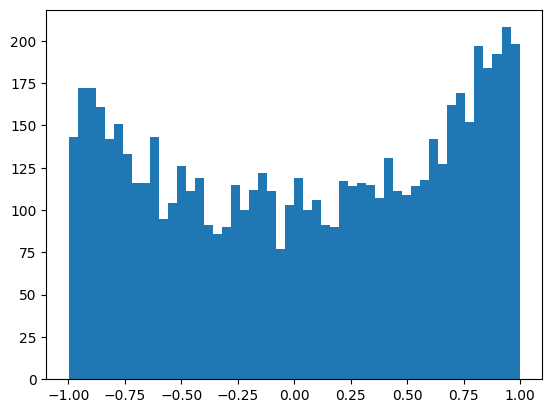

In [41]:
plt.hist(h.view(-1).tolist(), 50)

(array([  1.,   2.,   0.,   1.,   5.,   3.,  11.,   6.,  13.,  10.,  25.,
         40.,  40.,  77.,  63., 101., 127., 171., 184., 220., 227., 267.,
        312., 301., 356., 367., 376., 360., 370., 331., 298., 278., 292.,
        242., 191., 167., 137., 104.,  85.,  77.,  41.,  30.,  28.,  20.,
         11.,   7.,  11.,   5.,   2.,   7.]),
 array([-3.76367092, -3.62009715, -3.47652338, -3.33294961, -3.18937584,
        -3.04580207, -2.9022283 , -2.75865453, -2.61508076, -2.47150699,
        -2.32793322, -2.18435945, -2.04078568, -1.8972119 , -1.75363813,
        -1.61006436, -1.46649059, -1.32291682, -1.17934305, -1.03576928,
        -0.89219551, -0.74862174, -0.60504797, -0.4614742 , -0.31790043,
        -0.17432666, -0.03075289,  0.11282088,  0.25639465,  0.39996842,
         0.54354219,  0.68711596,  0.83068974,  0.97426351,  1.11783728,
         1.26141105,  1.40498482,  1.54855859,  1.69213236,  1.83570613,
         1.9792799 ,  2.12285367,  2.26642744,  2.41000121,  2.55357498,
 

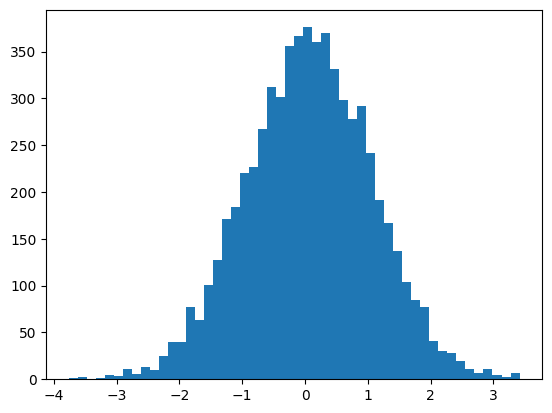

In [42]:
plt.hist(hpreact.view(-1).tolist(), 50)

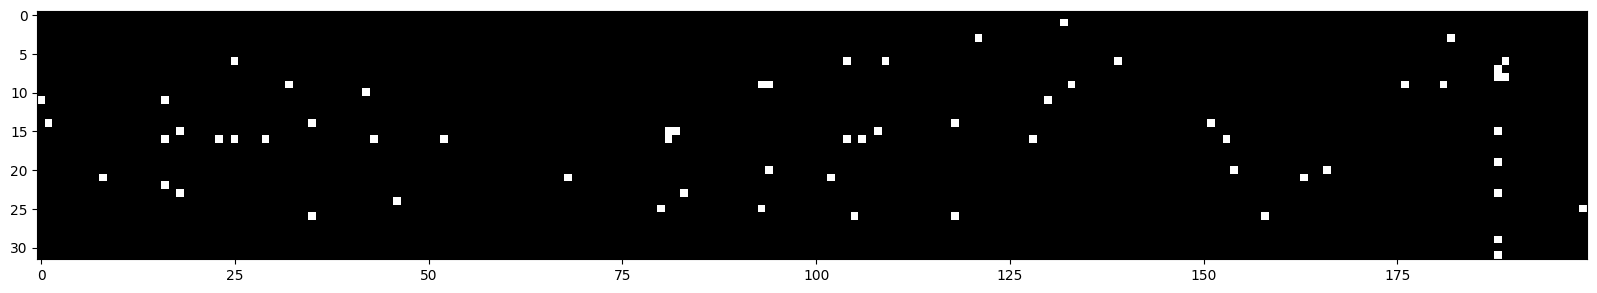

In [43]:
plt.figure(figsize=(20,10))
plt.imshow(h.abs() > 0.99 , cmap = 'gray', interpolation='nearest')

In [44]:
# This is much better and preferable

In [45]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * 0.2     #*******imp.
b1 = torch.randn(n_hidden, generator=g) * 0.01                          #*******imp.

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3135
  10000/ 200000: 2.1648
  20000/ 200000: 2.3061
  30000/ 200000: 2.4541
  40000/ 200000: 1.9787
  50000/ 200000: 2.2930
  60000/ 200000: 2.4232
  70000/ 200000: 2.0680
  80000/ 200000: 2.3095
  90000/ 200000: 2.1207
 100000/ 200000: 1.8269
 110000/ 200000: 2.2045
 120000/ 200000: 1.9797
 130000/ 200000: 2.3946
 140000/ 200000: 2.1000
 150000/ 200000: 2.1948
 160000/ 200000: 1.8619
 170000/ 200000: 1.7809
 180000/ 200000: 1.9673
 190000/ 200000: 1.8295


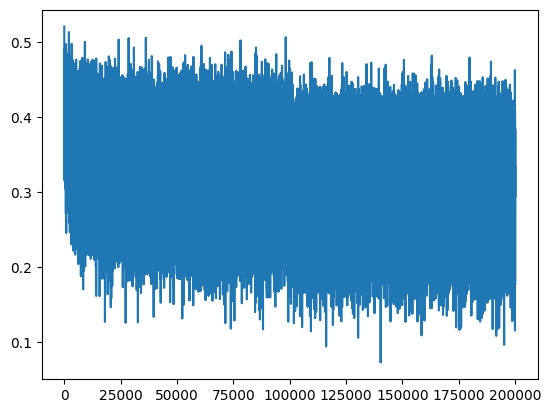

In [46]:
plt.plot(lossi)

In [47]:
split_loss('train')
split_loss('test')

train: 2.0356
test: 2.1012


In [48]:
# Sample from the model
# Lets try creating new words using our model

g = torch.Generator().manual_seed(2147482647 + 10)

for _ in range(20):

  out = []
  context = [0]*block_size

  while True:
    # forward pass
    emb = C[torch.tensor(context)]
    embcat = emb.view(1, -1)
    h = torch.tanh(embcat @ W1 + b1)
    logits = h @ W2 + b2

    probs = F.softmax(logits, dim = 1)
    ix = torch.multinomial(probs, num_samples=1, generator=g).item()

    context = context[1:] + [ix]
    out.append(ix)

    if ix == 0:
      break

  print(''.join(itos[i] for i in out))

nyeldiquel.
hen.
ell.
ose.
leesham.
breki.
jna.
ospell.
bhilah.
hanko.
azaina.
janyann.
haiza.
kryn.
inn.
mizier.
coranti.
has.
dilee.
aly.


In [49]:
# 2 issues we had fixed

# 1. Softmax confidently wrong
# 2. tanh layer too saturated at init

tensor(-0.0084) tensor(0.9975)
tensor(0.0032) tensor(3.2076)


(array([1.38071900e-05, 2.07107850e-05, 2.76143800e-05, 6.90359501e-05,
        5.52287601e-05, 6.90359501e-05, 2.83047395e-04, 4.14215700e-04,
        7.45588261e-04, 1.22883991e-03, 2.02275334e-03, 3.64509816e-03,
        5.19150345e-03, 7.82177314e-03, 1.28337831e-02, 1.92058013e-02,
        2.79181382e-02, 3.95161778e-02, 5.45038826e-02, 7.29226741e-02,
        9.17211633e-02, 1.11299759e-01, 1.25348575e-01, 1.33612178e-01,
        1.31686075e-01, 1.20032806e-01, 1.06902169e-01, 8.59704686e-02,
        6.71098471e-02, 5.06171586e-02, 3.55258999e-02, 2.47424845e-02,
        1.67895431e-02, 1.13080886e-02, 6.99334174e-03, 4.91535965e-03,
        3.19636449e-03, 1.85016346e-03, 1.03553925e-03, 6.42034336e-04,
        4.00408510e-04, 2.55433015e-04, 1.38071900e-04, 6.21323551e-05,
        1.38071900e-05, 2.07107850e-05, 0.00000000e+00, 6.90359501e-06,
        6.90359501e-06, 6.90359501e-06]),
 array([-17.27454758, -16.55028725, -15.82602692, -15.10176659,
        -14.37750626, -13.6532

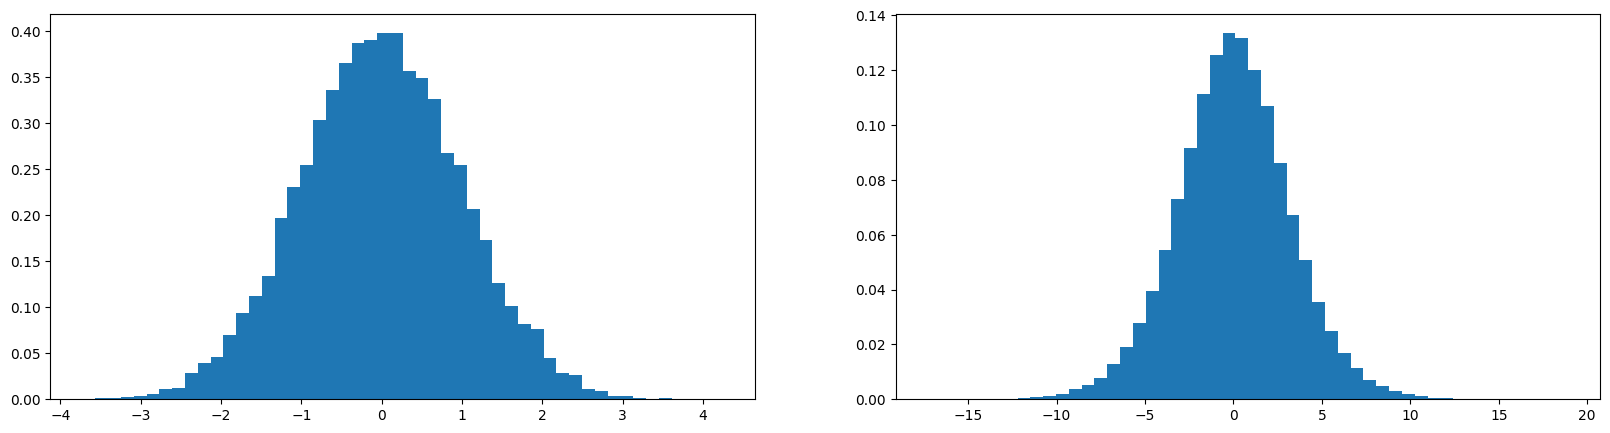

In [50]:
# Ex.
x = torch.randn(1000, 10)
w = torch.randn(10, 200)
y = x @ w

print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density = True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density = True)

In [51]:
# in this histrogram we can see
# for input (x) ---> mean is approx. 0 and std is approx. 1
# for output (y) ---> mean is approx. 0 but the std is approx. 3

# thats mean the graph extended horizontally
# the gausian is expanding
# we dont want that
# we want all the neuron to have relatively similar activations

tensor(0.0015) tensor(0.9978)
tensor(-0.0014) tensor(0.6385)


(array([6.68044005e-05, 0.00000000e+00, 1.33608801e-04, 5.01033004e-04,
        4.67630804e-04, 7.34848406e-04, 1.67011001e-03, 2.10433862e-03,
        4.44249264e-03, 7.21487526e-03, 1.15571613e-02, 1.95068850e-02,
        2.93605340e-02, 4.50929704e-02, 6.99108052e-02, 1.09626021e-01,
        1.60029941e-01, 2.24329177e-01, 3.10573658e-01, 4.06270962e-01,
        5.16631832e-01, 5.97030928e-01, 6.73755782e-01, 6.79333949e-01,
        6.29464464e-01, 5.62927281e-01, 4.53100847e-01, 3.48718971e-01,
        2.63008925e-01, 1.89958313e-01, 1.28732080e-01, 8.47079799e-02,
        5.44121842e-02, 3.87465523e-02, 2.14108104e-02, 1.25926295e-02,
        8.98519187e-03, 5.71177625e-03, 3.13980683e-03, 1.93732762e-03,
        1.13567481e-03, 3.00619802e-04, 4.00826403e-04, 4.00826403e-04,
        1.00206601e-04, 1.67011001e-04, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 3.34022003e-05]),
 array([-3.47721934, -3.32752861, -3.17783787, -3.02814713, -2.87845639,
        -2.72876565, 

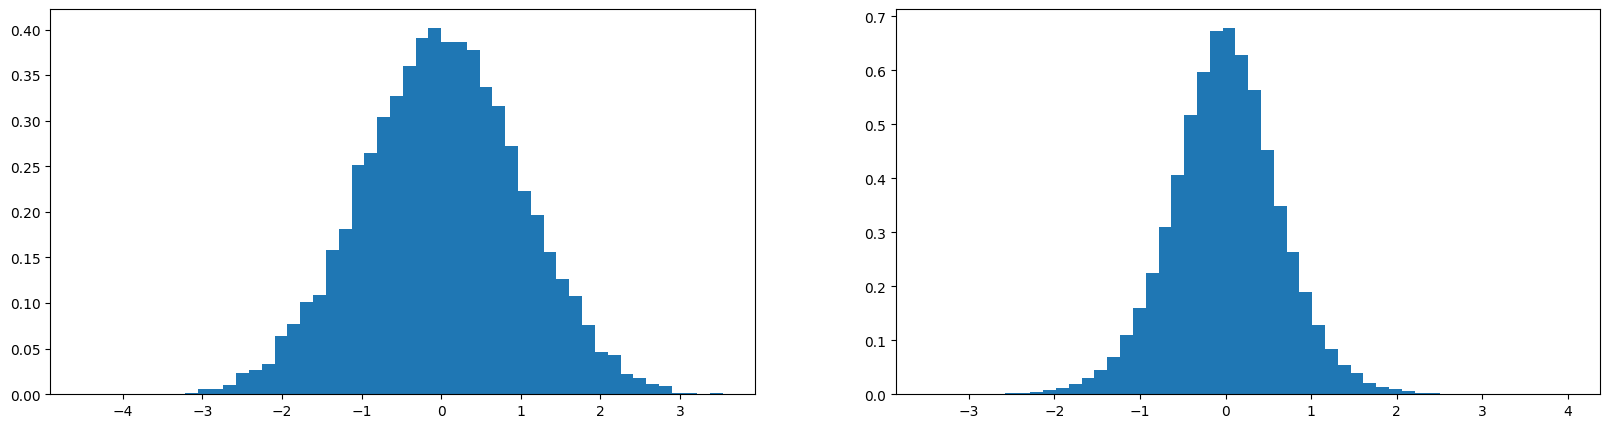

In [52]:
# Ex.
x = torch.randn(1000, 10)
w = torch.randn(10, 200) * 0.2              #**********
y = x @ w

print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density = True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density = True)

In [53]:
# after multpling W with '0.2' we get std for y as 0.6

# so we know we have to mult something to w to achieve our goal (all neuron have relatively similar activations)

# how to decide which number to mult w to?

In [54]:
# Multiply the 'w' with 1/(sq. root of fan in)

# fan in is number of inputs

tensor(-0.0036) tensor(1.0092)
tensor(0.0006) tensor(0.9842)


(array([2.12485785e-05, 0.00000000e+00, 4.24971570e-05, 2.12485785e-05,
        6.37457355e-05, 8.49943141e-05, 8.49943141e-05, 3.39977256e-04,
        6.37457355e-04, 7.22451670e-04, 1.52989765e-03, 2.59232658e-03,
        3.97348418e-03, 7.33075959e-03, 1.21966841e-02, 1.95911894e-02,
        2.94930270e-02, 4.98916624e-02, 7.38388103e-02, 1.13191178e-01,
        1.58068176e-01, 2.15354343e-01, 2.82776083e-01, 3.49475371e-01,
        4.07823967e-01, 4.32578561e-01, 4.30538698e-01, 3.95946012e-01,
        3.37066201e-01, 2.72619262e-01, 2.04198840e-01, 1.48740050e-01,
        1.03693063e-01, 7.37325674e-02, 4.54719580e-02, 2.98117557e-02,
        1.83375233e-02, 1.12829952e-02, 6.26833066e-03, 4.22846712e-03,
        2.16735501e-03, 1.52989765e-03, 7.01203091e-04, 4.24971570e-04,
        4.67468727e-04, 3.61225835e-04, 1.69988628e-04, 1.27491471e-04,
        4.24971570e-05, 6.37457355e-05]),
 array([-6.10012913, -5.86481927, -5.62950941, -5.39419955, -5.15888969,
        -4.92357984, 

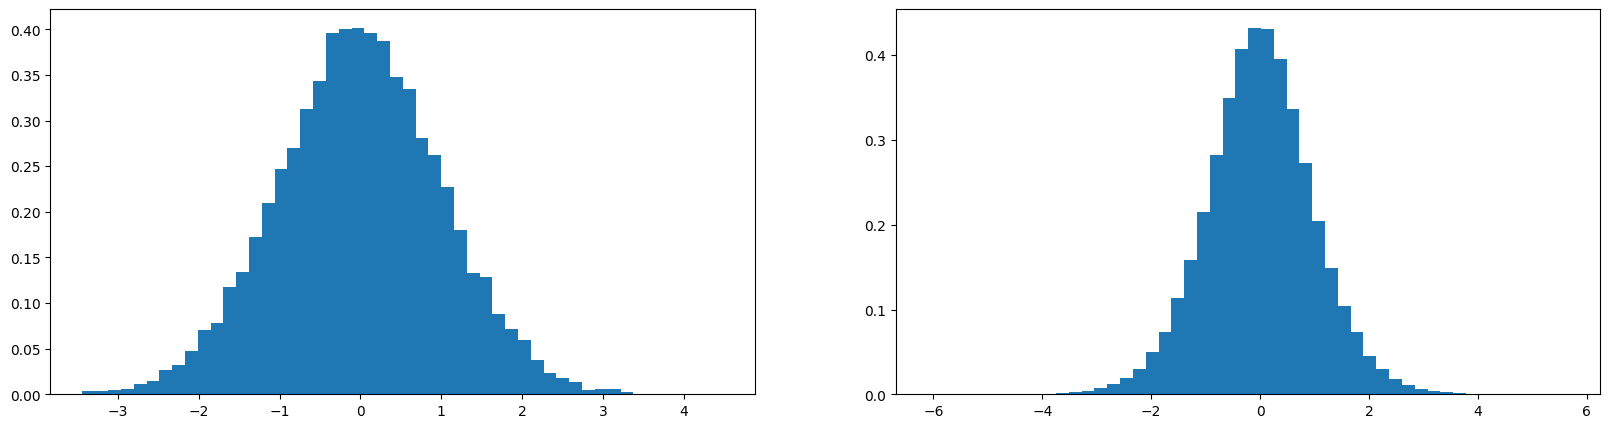

In [55]:
# Ex.
x = torch.randn(1000, 10)
w = torch.randn(10, 200) / 10**0.5        #**************************** imp.
y = x @ w

print(x.mean(), x.std())
print(y.mean(), y.std())

plt.figure(figsize=(20, 5))
plt.subplot(121)
plt.hist(x.view(-1).tolist(), 50, density = True)
plt.subplot(122)
plt.hist(y.view(-1).tolist(), 50, density = True)

In [56]:
# excat number to multiply is

# gain / (sq. root of fan in)

# got linear ---> gain = 1
# for tanh -----> gain = 5/3
# for relu -----> gain = 2**0.5
# ...

In [57]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

# *************************************************************************************************very imp.
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * (5/3)/((block_size * n_emb)**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1
  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3179
  10000/ 200000: 2.1910
  20000/ 200000: 2.3270
  30000/ 200000: 2.5396
  40000/ 200000: 1.9468
  50000/ 200000: 2.3331
  60000/ 200000: 2.3852
  70000/ 200000: 2.1173
  80000/ 200000: 2.3159
  90000/ 200000: 2.2010
 100000/ 200000: 1.8591
 110000/ 200000: 2.0881
 120000/ 200000: 1.9389
 130000/ 200000: 2.3913
 140000/ 200000: 2.0949
 150000/ 200000: 2.1458
 160000/ 200000: 1.7824
 170000/ 200000: 1.7249
 180000/ 200000: 1.9752
 190000/ 200000: 1.8614


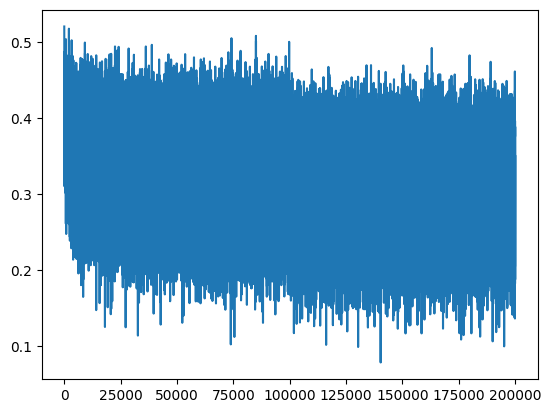

In [58]:
plt.plot(lossi)

In [59]:
split_loss('train')
split_loss('test')

train: 2.0377
test: 2.1050


In [60]:
hpreact.shape

torch.Size([32, 200])

In [61]:
hpreact.mean(0, keepdim=True).shape

torch.Size([1, 200])

In [62]:
hpreact.mean(1, keepdim=True).shape

torch.Size([32, 1])

In [63]:
# Batch Normalization

# here we will normalize the hpreact before it goes through activation

In [64]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

# *************************************************************************************************very imp.
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * (5/3)/((block_size * n_emb)**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

parameters = [C, W1, b1, W2, b2]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1 + b1
  hpreact = (hpreact - hpreact.mean(0, keepdim=True)) / (hpreact.std(0, keepdim=True))

  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3147
  10000/ 200000: 2.1942
  20000/ 200000: 2.3443
  30000/ 200000: 2.4160
  40000/ 200000: 1.9913
  50000/ 200000: 2.2978
  60000/ 200000: 2.5254
  70000/ 200000: 2.0707
  80000/ 200000: 2.3107
  90000/ 200000: 2.0663
 100000/ 200000: 1.9933
 110000/ 200000: 2.3179
 120000/ 200000: 1.9123
 130000/ 200000: 2.4505
 140000/ 200000: 2.4321
 150000/ 200000: 2.2003
 160000/ 200000: 2.0463
 170000/ 200000: 1.8839
 180000/ 200000: 1.9983
 190000/ 200000: 1.8873


In [65]:
# Here the problem is
# we want hpreact to be Roughly gausian but only at initilization
# We dont want it to be forced to be gausian always
# We like the neural net to move this (hist graph) around
# to make it potentially more diffuse  to make it more sharpe
# to some (ex. 10) neuron maybe to more trigger happy or less trigger happy

# so we like this dirtibution (hist graph) to move around and
# we want backpropogation to tell us how teh distribution should move around

# Thus we will scale and shift ----- according to research paper
# we will introduce 2 varibale 'gain' and 'bias'
# hpreact = gain * hpreact_normalize + bias
# we are SCALING hpreact_normalize with some 'gain' and OFFSETTING them by some 'bias'

In [66]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

# *************************************************************************************************very imp.
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * (5/3)/((block_size * n_emb)**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

# Batch Normalization - gain and bias
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
for p in parameters:
  p.requires_grad = True
max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1 + b1
  hpreact = bngain * ( (hpreact - hpreact.mean(0, keepdim=True)) / (hpreact.std(0, keepdim=True)) ) + bnbias

  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

      0/ 200000: 3.3147
  10000/ 200000: 2.1984
  20000/ 200000: 2.3375
  30000/ 200000: 2.4359
  40000/ 200000: 2.0119
  50000/ 200000: 2.2595
  60000/ 200000: 2.4775
  70000/ 200000: 2.1020
  80000/ 200000: 2.2788
  90000/ 200000: 2.1862
 100000/ 200000: 1.9474
 110000/ 200000: 2.3010
 120000/ 200000: 1.9837
 130000/ 200000: 2.4523
 140000/ 200000: 2.3839
 150000/ 200000: 2.1987
 160000/ 200000: 1.9733
 170000/ 200000: 1.8668
 180000/ 200000: 1.9973
 190000/ 200000: 1.8347


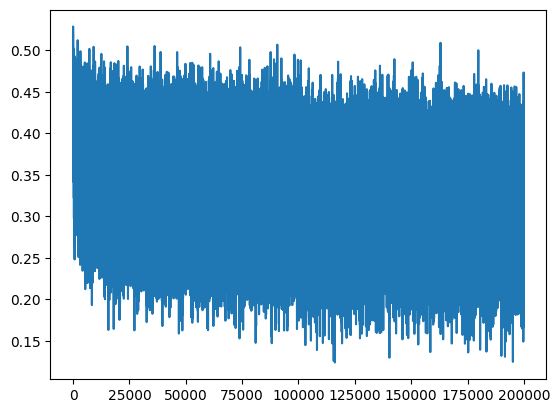

In [67]:
plt.plot(lossi)

In [68]:
@torch.no_grad()          # This decorator disables gradient tracking *************************
def split_loss(split: str):

  x, y = {
      'train': (Xtr, Ytr),
      'val': (Xdev, Ydev),
      'test': (Xte, Yte)
  }[split]

  emb = C[x]

  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1 + b1
  hpreact = bngain * ( (hpreact - hpreact.mean(0, keepdim=True)) / (hpreact.std(0, keepdim=True)) ) + bnbias

  h = torch.tanh(hpreact)

  logits = h @ W2 + b2

  loss = F.cross_entropy(logits, y)
  print(f'{split}: {loss:.4f}')

split_loss('train')
split_loss('val')

train: 2.0668
val: 2.1048


In [69]:
# Here there is an issue
# as we are normalizing accross column when calculating mean and std
# it taakes all example into consideration
# thus, it will expect the batch as an input everytime
# But,
# when we want to predict we give 1 example and expect an predicted output

# So we have to set a mean and std after the training
# which we can use during prediction


# NOTE: Batch Normalization have teh regularization effect

In [71]:
# calibrate teh batch norm at teh end of teh trainig

with torch.no_grad():
  # pass teh training set through
  emb = C[Xtr]
  embcat = emb.view(emb.shape[0], -1)
  hpreact = embcat @ W1 + b1

  # measure the mean and std of the entire training set
  bnmean = hpreact.mean(0, keepdim=True)
  bnstd = hpreact.std(0, keepdim = True)

In [72]:
@torch.no_grad()          # This decorator disables gradient tracking *************************
def split_loss(split: str):

  x, y = {
      'train': (Xtr, Ytr),
      'val': (Xdev, Ydev),
      'test': (Xte, Yte)
  }[split]

  emb = C[x]

  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean) / (bnstd)  + bnbias

  h = torch.tanh(hpreact)

  logits = h @ W2 + b2

  loss = F.cross_entropy(logits, y)
  print(f'{split}: {loss:.4f}')

split_loss('train')
split_loss('val')

train: 2.0668
val: 2.1049


In [73]:
# Here we have to define bnmean and bnstd after training
# and no one likes to do it
# so

# We can estimate bnmean and bnstd in an running manner - during trainig
# during training - we are also estimiting bnmean and bnstd

In [74]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

# *************************************************************************************************very imp.
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * (5/3)/((block_size * n_emb)**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

# Batch Normalization - gain and bias
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, b1, W2, b2, bngain, bnbias]
for p in parameters:
  p.requires_grad = True

print(f'Total parameters = {sum(p.nelement() for p in parameters)}\n')

max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1 + b1
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)
  hpreact = bngain * (hpreact - bnmeani) / (bnstdi) + bnbias

  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

Total parameters = 12297

      0/ 200000: 3.3147
  10000/ 200000: 2.1984
  20000/ 200000: 2.3375
  30000/ 200000: 2.4359
  40000/ 200000: 2.0119
  50000/ 200000: 2.2595
  60000/ 200000: 2.4775
  70000/ 200000: 2.1020
  80000/ 200000: 2.2788
  90000/ 200000: 2.1862
 100000/ 200000: 1.9474
 110000/ 200000: 2.3010
 120000/ 200000: 1.9837
 130000/ 200000: 2.4523
 140000/ 200000: 2.3839
 150000/ 200000: 2.1987
 160000/ 200000: 1.9733
 170000/ 200000: 1.8668
 180000/ 200000: 1.9973
 190000/ 200000: 1.8347


In [84]:
print(bnmean[0][:10])
print(bnmean_running[0][:10],'\n')

print(bnstd[0][:10])
print(bnstd_running[0][:10])

tensor([-2.3355,  0.6776, -0.9133,  1.0163,  1.0865,  1.0938,  1.7437, -2.1208,
         0.5730,  1.4455])
tensor([-2.3539,  0.6872, -0.9000,  1.0159,  1.0894,  1.0862,  1.7389, -2.1356,
         0.5608,  1.4246]) 

tensor([2.3929, 2.1364, 2.2663, 1.9944, 2.1860, 2.3736, 2.2576, 2.3451, 2.3578,
        2.1045])
tensor([2.3689, 2.0998, 2.2499, 1.9599, 2.1515, 2.3429, 2.2431, 2.3104, 2.3309,
        2.0823])


In [85]:
@torch.no_grad()          # This decorator disables gradient tracking *************************
def split_loss(split: str):

  x, y = {
      'train': (Xtr, Ytr),
      'val': (Xdev, Ydev),
      'test': (Xte, Yte)
  }[split]

  emb = C[x]

  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1 + b1
  hpreact = bngain * (hpreact - bnmean_running) / (bnstd_running)  + bnbias

  h = torch.tanh(hpreact)

  logits = h @ W2 + b2

  loss = F.cross_entropy(logits, y)
  print(f'{split}: {loss:.4f}')

split_loss('train')
split_loss('val')

train: 2.0666
val: 2.1051


In [86]:

#  2 small details

# 1.
# normalization = (x-mean) / (std**2 + e)**0.5
# e = is very small number
# we use this in case std is zero
# we have to prevent division by zero

# 2.
# b1 - its useless
# hpreact = embcat @ W1 + b1
# bnmeani = hpreact.mean(0, keepdim=True)
# bnstdi = hpreact.std(0, keepdim=True)
# hpreact = bngain * (hpreact - bnmeani) / (bnstdi) + bnbias
# b1 is useless because
# we are doing (hpreact - bnmeani) - which subract the b1 from b1
# so we can remove b1

In [87]:
# adding the above 2 points

In [89]:
n_emb = 10
n_hidden = 200
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((vocab_size, n_emb), generator=g)

# *************************************************************************************************very imp.
W1 = torch.randn((block_size * n_emb, n_hidden), generator=g) * (5/3)/((block_size * n_emb)**0.5)
# b1 = torch.randn(n_hidden, generator=g) * 0.01

W2 = torch.randn((n_hidden, vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0

# Batch Normalization - gain and bias
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))
bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))

parameters = [C, W1, W2, b2, bngain, bnbias]
for p in parameters:
  p.requires_grad = True

print(f'Total parameters = {sum(p.nelement() for p in parameters)}\n')

max_step = 200000
batch_size = 32
lossi = []

for i in range(max_step):

  # minibatch
  ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  # forward pass
  emb = C[Xb]
  embcat = emb.view(emb.shape[0], -1)

  # Batch Normalization
  hpreact = embcat @ W1
  bnmeani = hpreact.mean(0, keepdim=True)
  bnstdi = hpreact.std(0, keepdim=True)
  hpreact = bngain * (hpreact - bnmeani) / (bnstdi**2 + 0.001) + bnbias

  with torch.no_grad():
    bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
    bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

  h = torch.tanh(hpreact)
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Yb)

  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()

  # update
  lr = 0.1 if i<100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track status
  if i % 10000 == 0:
    print(f'{i:7d}/{max_step:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())

Total parameters = 12097

      0/ 200000: 3.3200
  10000/ 200000: 2.0756
  20000/ 200000: 2.6476
  30000/ 200000: 2.0096
  40000/ 200000: 2.2934
  50000/ 200000: 1.8659
  60000/ 200000: 2.0694
  70000/ 200000: 2.4427
  80000/ 200000: 2.3988
  90000/ 200000: 2.1425
 100000/ 200000: 2.3244
 110000/ 200000: 2.3682
 120000/ 200000: 1.6952
 130000/ 200000: 1.9977
 140000/ 200000: 2.2442
 150000/ 200000: 1.9952
 160000/ 200000: 2.1048
 170000/ 200000: 2.4860
 180000/ 200000: 2.1969
 190000/ 200000: 2.1259


In [90]:
split_loss('train')
split_loss('val')

train: 2.0825
val: 2.1174


In [91]:
# Summary
# We are using Batch Normalization to control the statistic of activation in neural net
# It is normal to sprinkle the batch normalization accross neural net
# and usually we will place it after layers that have multiplications
# for ex. linear layer or convolutional layer
# Batch Normalization internally have parameters - gain and bias - these are trained using back propogration
# It also have 2 buffers - mean and std - bnmean_running and bnstd_running
# these are not trained using back propogration
# these are trained using and custome update we have written while training mean=0.999*mean+0.1*mean_i

# Batch Normalization calculates mean and std of the activations  that are fedding into Batch Norm layer over that batch
# then it centering that batch to be unit (1) gausian (I think it centering the batch so that mean will be 1)
# Then, it offsetting and scaling it by using learned gain and bias (bngain and bnbias)
# on top of that it is keeping track of mean and std of current iteration and update the
# bnmean_current and bnstd_current accondinly (mean=0.999*mean+0.1*mean_i)
# bnmean_current and bnstd_current -- will later be used in prediction